# 34 · Inverse dynamics and computed-torque control, with and without model error

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from vlacourse import torque_panda

HOME = np.array([0, 0, 0, -1.571, 0, 1.571, -0.785])

def reference(t):
    amp = np.array([0.5, 0.3, 0.4, 0.4, 0.5, 0.4, 0.6])
    w = 2 * np.pi * 0.5
    q = HOME + amp * np.sin(w * t)
    qd = amp * w * np.cos(w * t)
    qdd = -amp * w**2 * np.sin(w * t)
    return q, qd, qdd

def scaled_model(mass_scale):
    """The controller's belief about the robot: same robot with all link masses/inertias scaled."""
    model, data = torque_panda()
    for b in range(1, model.nbody):
        model.body_mass[b] *= mass_scale
        model.body_inertia[b] *= mass_scale
    return model, data

def run(mode, ctrl_mass_scale=1.0, T=4.0, kp=100.0, kd=20.0):
    model, data = torque_panda()
    cmodel, cdata = scaled_model(ctrl_mass_scale)
    errs = []
    while data.time < T:
        q_d, qd_d, qdd_d = reference(data.time)
        e, ed = q_d - data.qpos[:7], qd_d - data.qvel[:7]
        if mode == "PD + gravity":
            cdata.qpos[:] = data.qpos; cdata.qvel[:] = 0
            mujoco.mj_forward(cmodel, cdata)
            tau = 600 * e + 50 * ed + cdata.qfrc_bias[:7]
        else:
            cdata.qpos[:] = data.qpos; cdata.qvel[:] = data.qvel
            cdata.qacc[:] = 0
            cdata.qacc[:7] = qdd_d + kp * e + kd * ed
            mujoco.mj_inverse(cmodel, cdata)
            tau = cdata.qfrc_inverse[:7]
        data.ctrl[:7] = tau; data.ctrl[7] = 255
        mujoco.mj_step(model, data)
        errs.append(np.linalg.norm(e))
    return np.array(errs)

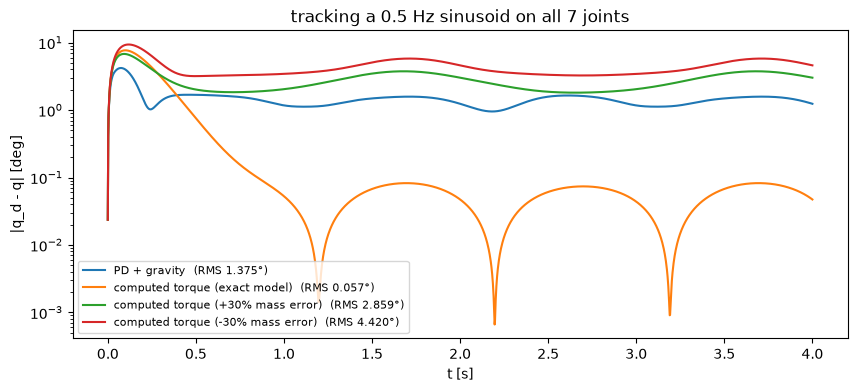

In [2]:
cases = {"PD + gravity": run("PD + gravity"), "computed torque (exact model)": run("CTC"),
         "computed torque (+30% mass error)": run("CTC", 1.3), "computed torque (-30% mass error)": run("CTC", 0.7)}
plt.figure(figsize=(10, 4))
for name, e in cases.items():
    plt.semilogy(np.arange(len(e)) * 0.002, np.degrees(e), label=f"{name}  (RMS {np.degrees(np.sqrt(np.mean(e[500:]**2))):.3f}°)")
plt.xlabel("t [s]"); plt.ylabel("|q_d - q| [deg]"); plt.legend(fontsize=8); plt.title("tracking a 0.5 Hz sinusoid on all 7 joints"); plt.show()

In [3]:
gains = [(25, 10), (100, 20), (400, 40)]
rms = []
for kp, kd in gains:
    e = run("CTC", 1.3, kp=kp, kd=kd)
    rms.append(np.degrees(np.sqrt(np.mean(e[500:] ** 2))))
print("computed torque with +30% mass error:")
for (kp, kd), r in zip(gains, rms):
    print(f"  kp={kp:4d} kd={kd:3d} -> RMS error {r:.3f} deg   (outer-loop feedback absorbs model error)")

computed torque with +30% mass error:
  kp=  25 kd= 10 -> RMS error 10.825 deg   (outer-loop feedback absorbs model error)
  kp= 100 kd= 20 -> RMS error 2.859 deg   (outer-loop feedback absorbs model error)
  kp= 400 kd= 40 -> RMS error 0.739 deg   (outer-loop feedback absorbs model error)
